In [5]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [6]:
def f(x):
    return x**2 + 4*x + 2

In [7]:
f(4)

34

In [8]:
xs = np.arange(-5,5,.25)

In [9]:
xs

array([-5.  , -4.75, -4.5 , -4.25, -4.  , -3.75, -3.5 , -3.25, -3.  ,
       -2.75, -2.5 , -2.25, -2.  , -1.75, -1.5 , -1.25, -1.  , -0.75,
       -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ,  1.25,  1.5 ,
        1.75,  2.  ,  2.25,  2.5 ,  2.75,  3.  ,  3.25,  3.5 ,  3.75,
        4.  ,  4.25,  4.5 ,  4.75])

In [10]:
ys = f(xs)

In [11]:
ys


array([ 7.    ,  5.5625,  4.25  ,  3.0625,  2.    ,  1.0625,  0.25  ,
       -0.4375, -1.    , -1.4375, -1.75  , -1.9375, -2.    , -1.9375,
       -1.75  , -1.4375, -1.    , -0.4375,  0.25  ,  1.0625,  2.    ,
        3.0625,  4.25  ,  5.5625,  7.    ,  8.5625, 10.25  , 12.0625,
       14.    , 16.0625, 18.25  , 20.5625, 23.    , 25.5625, 28.25  ,
       31.0625, 34.    , 37.0625, 40.25  , 43.5625])

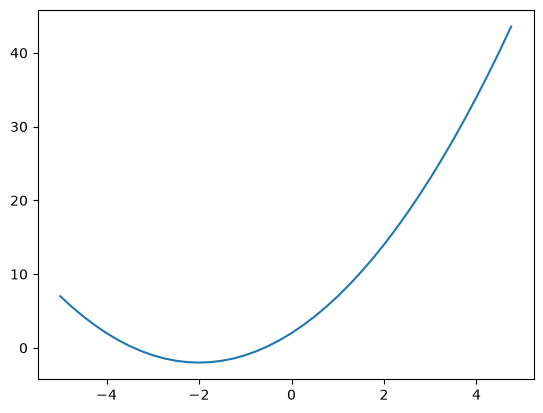

In [12]:
plt.plot(xs,ys)
plt.show()

In [13]:
h=0.000001
x= -2.5
(f(x+h)-f(x))/h

-0.9999990000508774

In [14]:
a=20
b=30
c=-40
d= a*b+c
d

560

In [15]:
h=0.00001

a=2
b=3
c=-4
d1= a*b+c
c+=h
d2= a*b+c

print(d1)
print(d2)
print("slope",(d2-d1)/h)


2
2.00001
slope 1.0000000000065512


In [31]:
from graphviz import Digraph
def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes: 
            nodes. add (v) 
            for child in v._prev: 
                edges. add ( (child, v))
                build (child)
    build (root)
    return nodes, edges
def draw_dot(root):
    dot = Digraph (format='svg', graph_attr={' rankdir':'LR'}) # LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot. node (name = uid, label = "{%s | data %.4f | grad : %s}" % (n.label,n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot. node (name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        # connect ni to the op node of n2
        dot. edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

In [154]:
class Value:
    def __init__(self, data, _children=(), _op='', label = ''):
        self.data = data
        self._prev = set(_children)
        self._backward = lambda : None
        self._op = _op
        self.grad = 0
        self.label = label

    def __repr__(self):
        return f"Vlaue (Data={self.data})"
    
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1 * out.grad
            other.grad += 1 * out.grad

        out._backward = _backward
        return out
    def __neg__(self):
        return self*-1
    def __sub__(self, other):
        return self+(-other)
        # other = other if isinstance(other, Value) else Value(other)
        # out = Value(self.data - other.data, (self, other), '+')
        # def _backward():
        #     self.grad += 1 * out.grad
        #     other.grad += -1 * out.grad

        # out._backward = _backward
        # return out
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data*other.data,(self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
    
    def __pow__(self, other):
        # other = other if isinstance(other, Value) else Value(other) <- this wont work yet
        assert isinstance(other, (int, float)), "only supoorting int/flt values for now"
        out = Value(self.data ** other, (self,), '**')
        def _backward():
            self.grad += other*self.data**(other -1)*out.grad
            # other.grad += 
        out._backward = _backward
        return out
    def __rmul__(self,other):
        return self*other
    
    def __truediv__(self, other):
        # other = other if isinstance(other, Value) else Value(other)
        return self*other**-1

    def tanh(self):
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t, (self, ), 'tanh')
        def _backward():
            self.grad += (1- t**2) * out.grad
        out._backward = _backward
        return out
    
    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)
        
        self.grad=1

        for node in reversed(topo):
            node._backward()






In [145]:
a = Value(2.0)
b = Value(3)
c = a-b
c.grad=1
c._backward()

In [146]:
b.grad

0

In [112]:

x1 = Value(2, label='x1')
x2 = Value(0, label='x2')
w1 = Value(-3, label='w1')
w2 = Value(1, label='w2')
x1w1 = x1*w1; x1w1.label='x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'
b = Value(6.8813735870195432, label='b')
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label='x1w1+x2w2'

n = x1w1x2w2 + b; n.label='n'
o = n.tanh(); o.label='o'





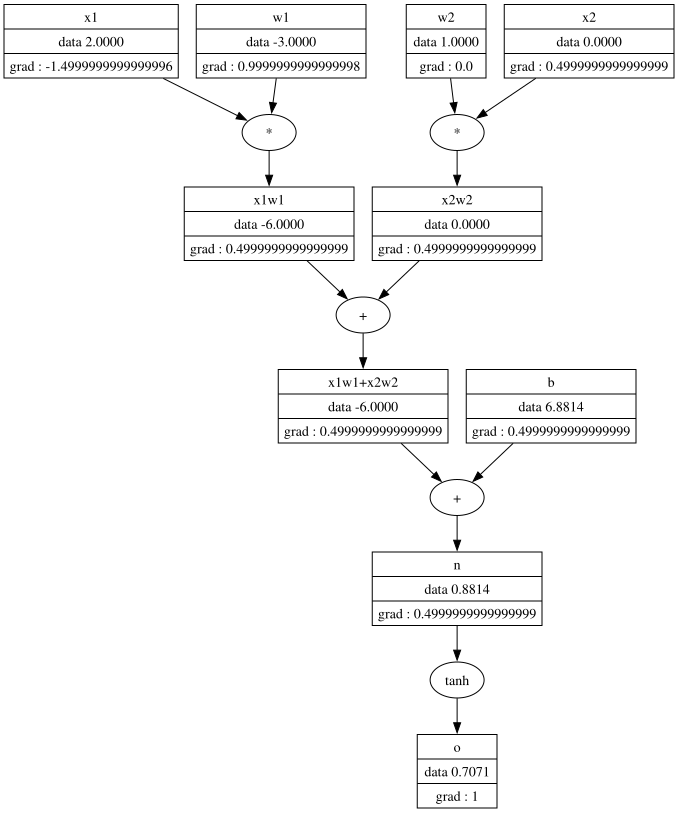

In [115]:
draw_dot(o)

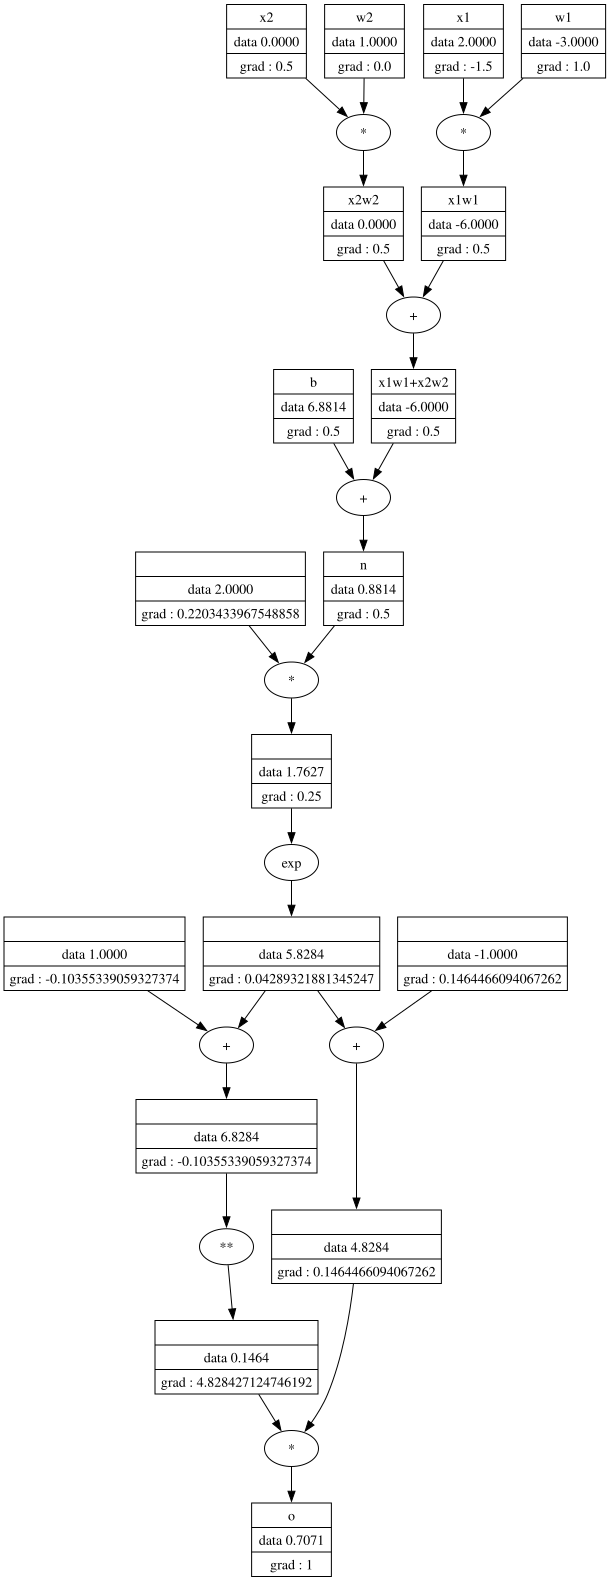

In [156]:
x1 = Value(2, label='x1')
x2 = Value(0, label='x2')
w1 = Value(-3, label='w1')
w2 = Value(1, label='w2')
x1w1 = x1*w1; x1w1.label='x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'
b = Value(6.8813735870195432, label='b')
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label='x1w1+x2w2'

n = x1w1x2w2 + b; n.label='n'
####
# tanh(n) = (e^2n -1) / (e^2n + 1)
e1= (2*n).exp()
o = (e1-1)/(e1+1)
####
o.label='o'
o.backward()
draw_dot(o)

Vlaue (Data=4.0)

In [162]:
import torch
import random


In [176]:
x1 = torch.tensor([2]).double();                    x1.requires_grad = True
w1 = torch.tensor([-3]).double();                   w1.requires_grad = True
x2 = torch.tensor([0]).double();                    x2.requires_grad = True
w2 = torch.tensor([1]).double();                    w2.requires_grad = True
b = torch.tensor([6.8813735870195432]).double();      b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)
print(o.data.item())
o.backward()

print("x1 :", x1.grad.item())
print("w1 :", w1.grad.item())
print("x2 :", x2.grad.item())
print("w2 :", w2.grad.item())

0.7071066904050358
x1 : -1.5000003851533106
w1 : 1.0000002567688737
x2 : 0.5000001283844369
w2 : 0.0


In [187]:

class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        act = sum((wi*xi for wi,xi in zip(self.w,x)), self.b)
        out = act.tanh()
        return out
    
class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs)==1 else outs
        

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin]+nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

x=[1,2]
n = MLP(2,[3,4,4,1])
n(x)


Vlaue (Data=-0.5570472769889089)

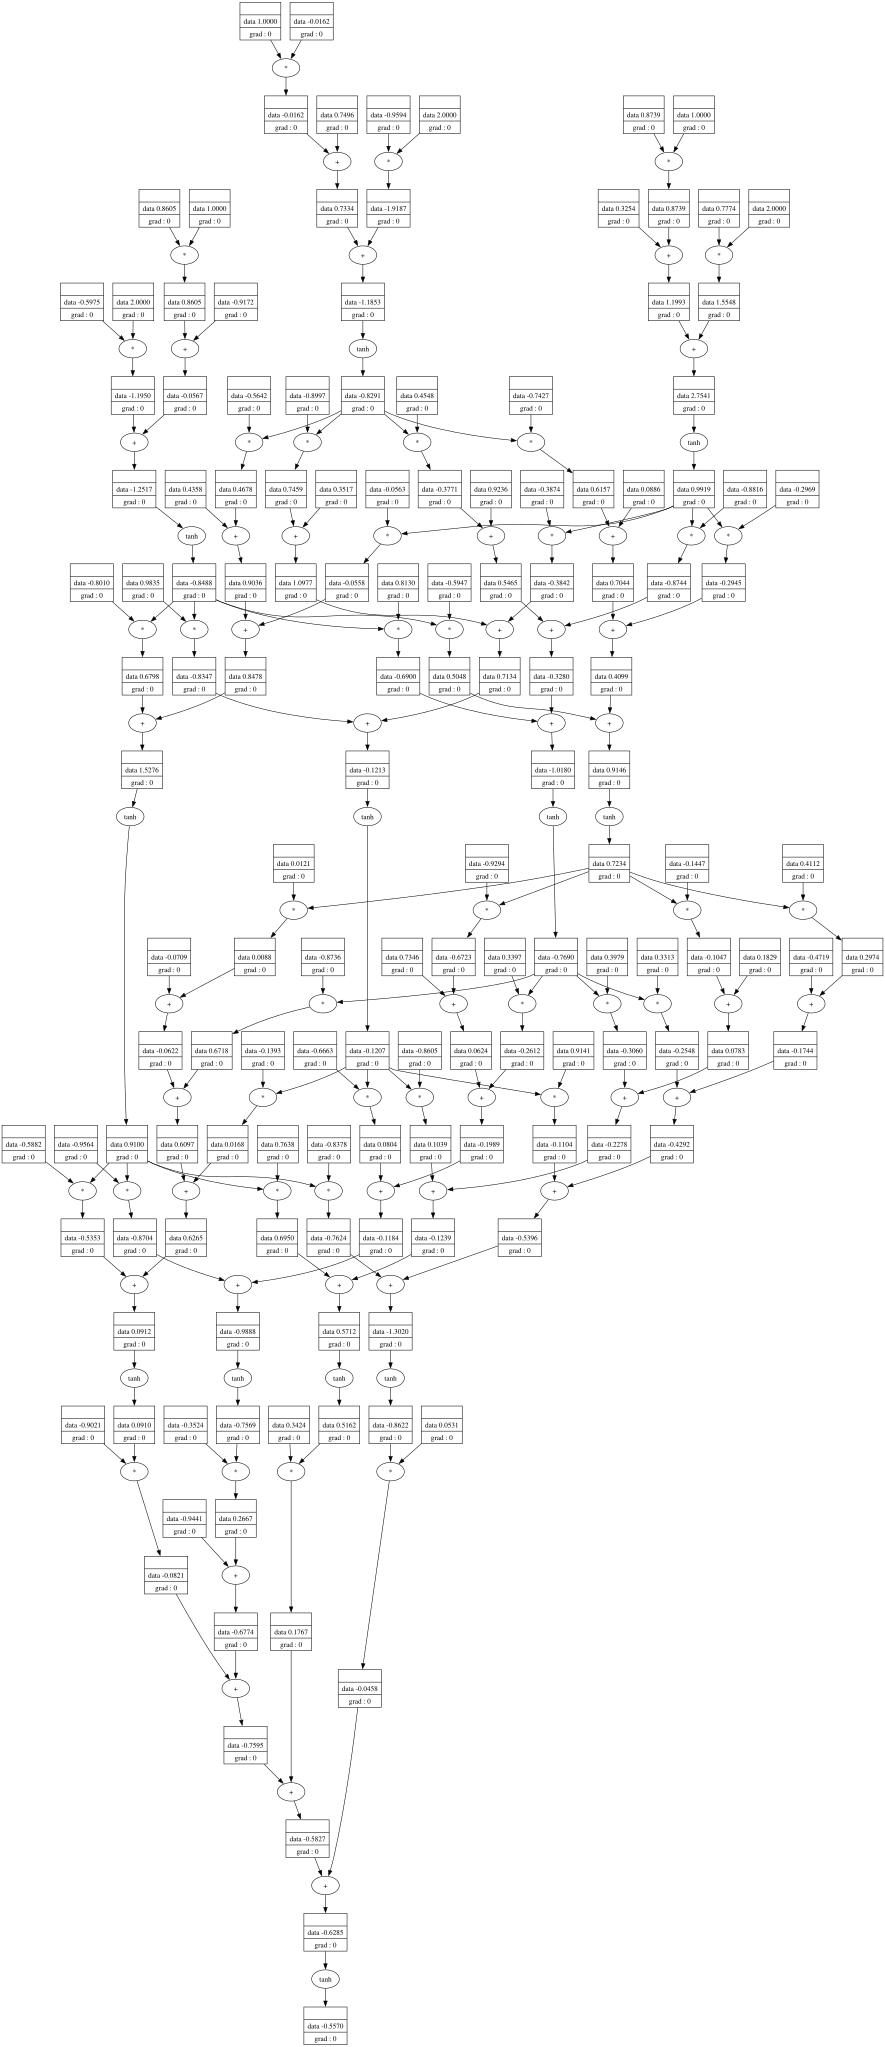

In [188]:
draw_dot(n(x))